# Static Visualisations with Matplotlib

In [35]:
import os
import geopandas as gpd
import contextily as cx
import geoplot.crs as gcrs
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import geoplot as gplt
import mapclassify as mc
import pandas as pd
from dotenv import load_dotenv, find_dotenv

In [36]:
# makes the inline-figures in notebooks look crisper
%config InlineBackend.figure_format = 'svg'

In [37]:
load_dotenv(find_dotenv(usecwd=True));

In [38]:
data_folder=os.getenv('DATA_FOLDER')

## Visualising the Swiss cantons

In [39]:
cantons = gpd.read_file(os.path.join(data_folder, 'swissboundaries', 'swissBOUNDARIES3D_1_4_TLM_KANTONSGEBIET.shp'))

In [40]:
cantons.columns

Index(['UUID', 'DATUM_AEND', 'DATUM_ERST', 'ERSTELL_J', 'ERSTELL_M',
       'REVISION_J', 'REVISION_M', 'GRUND_AEND', 'HERKUNFT', 'HERKUNFT_J',
       'HERKUNFT_M', 'OBJEKTART', 'REVISION_Q', 'ICC', 'KANTONSNUM',
       'SEE_FLAECH', 'KANTONSFLA', 'KT_TEIL', 'NAME', 'EINWOHNERZ',
       'geometry'],
      dtype='object')

In [41]:
cantons.head()

,UUID,DATUM_AEND,DATUM_ERST,ERSTELL_J,ERSTELL_M,REVISION_J,REVISION_M,GRUND_AEND,HERKUNFT,HERKUNFT_J,...,OBJEKTART,REVISION_Q,ICC,KANTONSNUM,SEE_FLAECH,KANTONSFLA,KT_TEIL,NAME,EINWOHNERZ,geometry
0,{0B2364ED-49E0-4D53-A33C-C684DD530B57},2018-11-22,2012-10-26,2012,10,2023,1,Verbessert,AV,2019,...,Kanton,sb3D_2022_Akt,CH,18,NaN,710530.0,0,Graubünden,201376.0,"POLYGON Z ((2735215.665 1194955.161 2870.714, ..."
1,{DDD56CEF-0E61-4EED-85ED-F67A459C93ED},2022-11-16,2012-10-26,2012,10,2023,1,Verbessert,AV,2023,...,Kanton,sb3D_2022_Akt,CH,2,11854.0,595850.0,1,Bern,1047422.0,"POLYGON Z ((2595241.51 1169313.282 2090.846, 2..."
2,{54B25E50-30A7-4995-ADE3-5FFF6E13A995},2022-11-14,2012-10-26,2012,10,2023,1,Verbessert,AV,2023,...,Kanton,sb3D_2022_Akt,CH,23,1060.0,522464.0,0,Valais,353209.0,"POLYGON Z ((2601807.628 1136116.777 2948.413, ..."
3,{921DFEF2-6D91-4CB8-9CFC-2A831C412020},2022-11-16,2012-10-26,2012,10,2023,1,Verbessert,AV,2023,...,Kanton,sb3D_2022_Akt,CH,22,38937.0,321202.0,1,Vaud,822968.0,"POLYGON Z ((2555092.813 1138713.419 372.133, 2..."
4,{95F10F52-8B2F-4D6A-AF7E-D4F915E42F89},2022-11-16,2012-10-26,2012,10,2023,1,Verbessert,AV,2023,...,Kanton,sb3D_2022_Akt,CH,21,7122.0,281215.0,0,Ticino,352181.0,"POLYGON Z ((2727358.511 1119219.094 1351.527, ..."


In [42]:
# remove all rows from canton besides name
# cantons = cantons[['NAME', 'geometry']]

**To do**: limit the content of the tooltips!

In [43]:
cantons.explore()

## Pointplots

**To Do:** 
* Scale the markersize by population number
* add a legend to the plot
* annotate each point with the canton name

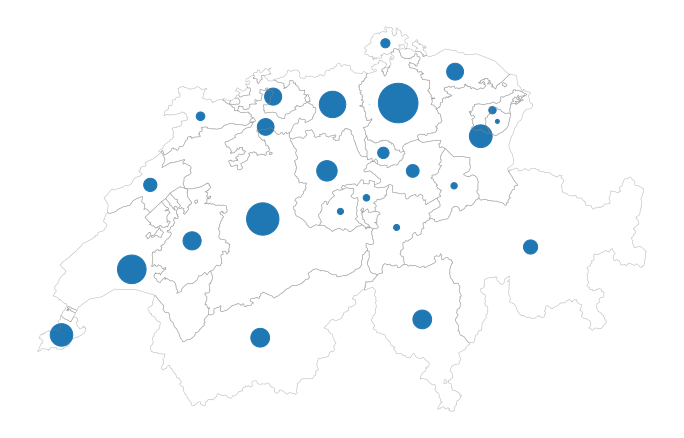

In [60]:
fig, ax = plt.subplots(figsize=(12,12))

cantons.boundary.plot(ax=ax, color='grey', linewidth=0.6, alpha=0.5)

cantons[~cantons['EINWOHNERZ'].isna()].centroid.plot(ax=ax, marker='o', color='tab:blue', markersize=cantons['EINWOHNERZ'].values/1000)

ax.spines[:].set_visible(False)


ax.tick_params(left = False, right = False , labelleft = False ,
                labelbottom = False, bottom = False)

plt.show()

## From Pointplots to density plots

In [61]:
boroughs = gpd.read_file(gplt.datasets.get_path("nyc_boroughs"))
collisions = gpd.read_file(gplt.datasets.get_path("nyc_collision_factors"))

In [62]:
boroughs

,BoroCode,BoroName,Shape_Leng,Shape_Area,geometry
0,5,Staten Island,330385.03697,1.623853e+09,"MULTIPOLYGON (((-74.05051 40.56642, -74.05047 ..."
1,4,Queens,861038.47930,3.049947e+09,"MULTIPOLYGON (((-73.83668 40.59495, -73.83678 ..."
2,3,Brooklyn,726568.94634,1.959432e+09,"MULTIPOLYGON (((-73.86706 40.58209, -73.86769 ..."
3,1,Manhattan,358532.95642,6.364422e+08,"MULTIPOLYGON (((-74.01093 40.68449, -74.01193 ..."
4,2,Bronx,464517.89055,1.186804e+09,"MULTIPOLYGON (((-73.89681 40.79581, -73.89694 ..."


In [63]:
boroughs.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [64]:
collisions

,id,ON STREET NAME,NUMBER OF MOTORIST KILLED,CONTRIBUTING FACTOR VEHICLE 3,NUMBER OF CYCLIST INJURED,LONGITUDE,OFF STREET NAME,VEHICLE TYPE CODE 4,LATITUDE,LOCATION,...,ZIP CODE,VEHICLE TYPE CODE 3,NUMBER OF CYCLIST KILLED,DATE,UNIQUE KEY,CONTRIBUTING FACTOR VEHICLE 5,VEHICLE TYPE CODE 5,TIME,NUMBER OF PEDESTRIANS INJURED,geometry
0,18,WORTMAN AVENUE,0,None,0,-73.872007,None,None,40.662514,"(40.6625139, -73.8720068)",...,11208.0,None,0,11/10/2016,3559576,None,None,16:11,0,POINT (-73.87201 40.66251)
1,21,HUBERT STREET,0,None,0,-74.008344,None,None,40.721323,"(40.7213228, -74.0083444)",...,10013.0,None,0,11/10/2016,3557391,None,None,5:11,1,POINT (-74.00834 40.72132)
2,69,HENRY STREET,0,None,0,-73.997563,None,None,40.687999,"(40.6879989, -73.9975625)",...,11201.0,None,0,04/16/2016,3419378,None,None,9:15,0,POINT (-73.99756 40.688)
3,80,None,0,Failure to Yield Right-of-Way,0,-73.854542,67-64 FLEET STREET,None,40.719228,"(40.7192276, -73.8545422)",...,11375.0,PASSENGER VEHICLE,0,04/15/2016,3428072,None,None,10:20,0,POINT (-73.85454 40.71923)
4,85,BEDFORD AVENUE,0,None,0,-73.952731,None,None,40.632147,"(40.6321467, -73.9527315)",...,11210.0,None,0,04/15/2016,3417537,None,None,10:35,0,POINT (-73.95273 40.63215)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7298,920212,EAST 11 STREET,0,None,0,-73.959113,None,None,40.584305,"(40.5843046, -73.9591125)",...,11235.0,None,0,01/07/2016,3367113,None,None,21:30,0,POINT (-73.95911 40.5843)
7299,920217,4 AVENUE,0,None,0,-74.020772,None,None,40.638583,"(40.6385828, -74.0207721)",...,11220.0,None,0,01/06/2016,3366075,None,None,12:50,0,POINT (-74.02077 40.63858)
7300,920263,SHORE BOULEVARD,0,None,0,-73.953836,None,None,40.581744,"(40.5817444, -73.9538363)",...,11235.0,None,0,01/04/2016,3365285,None,None,17:45,0,POINT (-73.95384 40.58174)
7301,920286,WEST 38 STREET,0,None,0,-73.982723,None,None,40.750960,"(40.7509597, -73.9827227)",...,10016.0,None,0,01/02/2016,3364048,None,None,17:20,0,POINT (-73.98272 40.75096)


In [ ]:
collisions.explore()

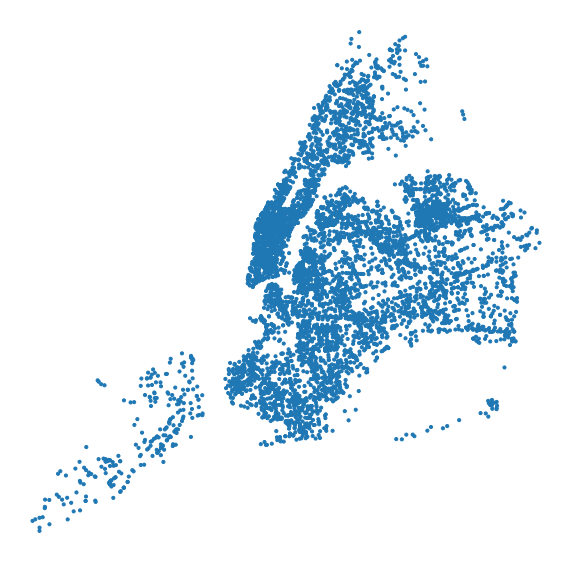

In [66]:
fig, ax = plt.subplots(figsize=(10,10))

# boroughs.to_crs(epsg=3857).plot(ax=ax, cmap='Pastel1', alpha=0.8)

collisions.to_crs(epsg=3857).plot(ax=ax, marker='o', color='tab:blue', markersize=10)

# cx.add_basemap(ax)

ax.spines[:].set_visible(False)


ax.tick_params(left = False, right = False , labelleft = False ,
                labelbottom = False, bottom = False)

plt.show()

In [67]:
collisions.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

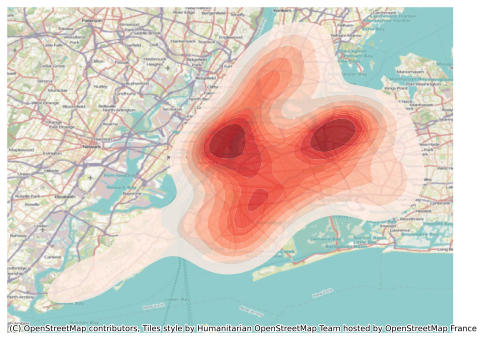

In [68]:
ax = gplt.kdeplot(
    collisions.head(1000), 
    # clip=boroughs,
     cmap='Reds', fill=True, alpha=0.8
)

cx.add_basemap(ax, crs=collisions.crs) # 'EPSG:5070'

# ax = gplt.polyplot(boroughs, projection=gcrs.AlbersEqualArea())
# gplt.kdeplot(collisions, cmap="Reds", fill=True, clip=boroughs, ax=ax)
plt.show()

## Choropleth maps

In [70]:
cantons['EWZ_REL'] = cantons['EINWOHNERZ']/cantons.area

In [71]:
fig, ax = plt.subplots(figsize=(12,12))

cantons.boundary.plot(ax=ax, color='grey', linewidth=0.6)
cantons.plot(ax=ax, column='EWZ_REL', cmap='RdBu_r', 
             norm=mpl.colors.LogNorm(vmin=cantons.EWZ_REL.min(), vmax=cantons.EWZ_REL.max()),
             legend=True,
            legend_kwds={"label": "Population in 2014 relative to area", "orientation": "vertical",
                        'location': 'right', 'shrink': 0.5}
            )

ax.spines[:].set_visible(False)


ax.tick_params(left = False, right = False , labelleft = False ,
                labelbottom = False, bottom = False)

plt.show()

## The Big Mac-price on a worldmap
**To do**:
* Merge the data frame with the big mac prizes with the geo dataframe of the world's countries boundaries
* Create a choropleth map coloring each country by big mac price

In [83]:
df_mac = pd.read_csv(os.path.join(data_folder, 'bigmac', 'big_mac_2020.csv'))
df_mac

,Unnamed: 0,iso_a3,year,dollar_price
0,15,ARE,2020,4.015736
1,36,ARG,2020,3.178060
2,57,AUS,2020,4.514798
3,60,AZE,2020,2.326610
4,63,BHR,2020,3.713282
5,84,BRA,2020,4.359043
6,105,CAN,2020,5.129163
7,126,CHE,2020,6.809426
8,147,CHL,2020,3.447448
9,168,CHN,2020,3.110591


In [73]:
worldne = gpd.read_file(os.path.join(data_folder, 'natural_earth', '110m_cultural', 'ne_110m_admin_0_countries.shp'))
for c in worldne.columns:
    print(c)

featurecla
scalerank
LABELRANK
SOVEREIGNT
SOV_A3
ADM0_DIF
LEVEL
TYPE
TLC
ADMIN
ADM0_A3
GEOU_DIF
GEOUNIT
GU_A3
SU_DIF
SUBUNIT
SU_A3
BRK_DIFF
NAME
NAME_LONG
BRK_A3
BRK_NAME
BRK_GROUP
ABBREV
POSTAL
FORMAL_EN
FORMAL_FR
NAME_CIAWF
NOTE_ADM0
NOTE_BRK
NAME_SORT
NAME_ALT
MAPCOLOR7
MAPCOLOR8
MAPCOLOR9
MAPCOLOR13
POP_EST
POP_RANK
POP_YEAR
GDP_MD
GDP_YEAR
ECONOMY
INCOME_GRP
FIPS_10
ISO_A2
ISO_A2_EH
ISO_A3
ISO_A3_EH
ISO_N3
ISO_N3_EH
UN_A3
WB_A2
WB_A3
WOE_ID
WOE_ID_EH
WOE_NOTE
ADM0_ISO
ADM0_DIFF
ADM0_TLC
ADM0_A3_US
ADM0_A3_FR
ADM0_A3_RU
ADM0_A3_ES
ADM0_A3_CN
ADM0_A3_TW
ADM0_A3_IN
ADM0_A3_NP
ADM0_A3_PK
ADM0_A3_DE
ADM0_A3_GB
ADM0_A3_BR
ADM0_A3_IL
ADM0_A3_PS
ADM0_A3_SA
ADM0_A3_EG
ADM0_A3_MA
ADM0_A3_PT
ADM0_A3_AR
ADM0_A3_JP
ADM0_A3_KO
ADM0_A3_VN
ADM0_A3_TR
ADM0_A3_ID
ADM0_A3_PL
ADM0_A3_GR
ADM0_A3_IT
ADM0_A3_NL
ADM0_A3_SE
ADM0_A3_BD
ADM0_A3_UA
ADM0_A3_UN
ADM0_A3_WB
CONTINENT
REGION_UN
SUBREGION
REGION_WB
NAME_LEN
LONG_LEN
ABBREV_LEN
TINY
HOMEPART
MIN_ZOOM
MIN_LABEL
MAX_LABEL
LABEL_X
LABEL_Y
NE_ID
WIKIDA

In [ ]:
worldne[['POP_EST', 'CONTINENT', 'NAME', 'ISO_A3', 'GDP_MD', 'geometry']]

In [ ]:
# rename the header of the df_mac to Uppercase
df_mac.columns = df_mac.columns.str.upper()
df_mac

In [88]:
# join the datasets df_mac and worldne by ISO_A3

dat = df_mac.merge(worldne, left_on='ISO_A3', right_on='ISO_A3', how='inner')
dat

,UNNAMED: 0,ISO_A3,YEAR,DOLLAR_PRICE,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,15,ARE,2020,4.015736,Admin-0 country,1,4,United Arab Emirates,ARE,0,...,None,None,None,None,None,None,None,None,None,"POLYGON ((51.57952 24.2455, 51.75744 24.29407,..."
1,36,ARG,2020,3.178060,Admin-0 country,1,2,Argentina,ARG,0,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-68.63401 -52.63637, -68.25 -5..."
2,57,AUS,2020,4.514798,Admin-0 country,1,2,Australia,AU1,1,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((147.68926 -40.80826, 148.28907..."
3,60,AZE,2020,2.326610,Admin-0 country,1,5,Azerbaijan,AZE,0,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((46.40495 41.86068, 46.68607 41..."
4,84,BRA,2020,4.359043,Admin-0 country,1,2,Brazil,BRA,0,...,None,None,None,None,None,None,None,None,None,"POLYGON ((-53.37366 -33.76838, -53.65054 -33.2..."
5,105,CAN,2020,5.129163,Admin-0 country,1,2,Canada,CAN,0,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025..."
6,126,CHE,2020,6.809426,Admin-0 country,1,4,Switzerland,CHE,0,...,None,None,None,None,None,None,None,None,None,"POLYGON ((9.59423 47.52506, 9.63293 47.3476, 9..."
7,147,CHL,2020,3.447448,Admin-0 country,1,2,Chile,CHL,0,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-68.63401 -52.63637, -68.63335..."
8,168,CHN,2020,3.110591,Admin-0 country,1,2,China,CH1,1,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((109.47521 18.1977, 108.65521 1..."
9,185,COL,2020,3.454822,Admin-0 country,1,2,Colombia,COL,0,...,None,None,None,None,None,None,None,None,None,"POLYGON ((-66.87633 1.25336, -67.06505 1.13011..."


In [91]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))

AttributeError: The geopandas.dataset has been deprecated and was removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.

In [90]:
world

NameError: name 'world' is not defined

In [79]:
world_merged = ...

## Cartograms

In [80]:
contiguous_usa = gpd.read_file (gplt.datasets.get_path ('contiguous_usa'))

In [81]:
scheme = mc.Quantiles(contiguous_usa['population'], k=5)

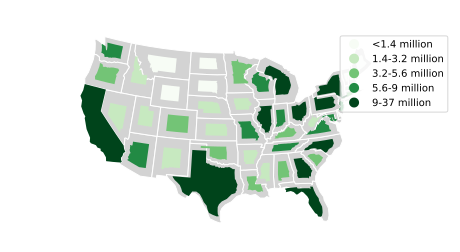

In [82]:
ax = gplt.cartogram(
    contiguous_usa, scale='population', projection=gcrs.AlbersEqualArea(),
    legend=True, legend_kwargs={'bbox_to_anchor': (1, 0.9)}, legend_var='hue',
    hue='population', scheme=scheme, cmap='Greens',
    legend_labels=[
        '<1.4 million', '1.4-3.2 million', '3.2-5.6 million',
        '5.6-9 million', '9-37 million'
    ],
    limits=(0.5, 1)
)
gplt.polyplot(contiguous_usa, facecolor='lightgray', edgecolor='white', ax=ax)

plt.show()